In [53]:
import dask.array as da

In [54]:
import dask.dataframe as dd

In [55]:
df = dd.read_parquet('/Users/aleksandrparinov/Desktop/trian/альфа')

In [56]:
df.head()

,amnt,currency,operation_kind,card_type,operation_type,operation_type_group,ecommerce_flag,payment_system,income_flag,mcc,country,city,mcc_category,day_of_week,hour,weekofyear,hour_diff,client_id
0,0.465425,1,4,98,4,2,3,7,3,2,1,37,2,4,19,34,-1,5feceb
1,0.000000,1,2,98,7,1,3,7,3,2,1,49,2,4,20,34,0,5feceb
2,0.521152,1,2,98,3,1,3,7,3,2,1,37,2,4,20,34,0,5feceb
3,0.356078,1,1,5,2,1,3,7,3,10,1,49,7,2,0,34,52,5feceb
4,0.000000,1,2,98,7,1,3,7,3,2,1,49,2,4,16,53,280,5feceb


In [57]:
df.shape[0].compute()

270450065

Для каждого клиента сформируй следующие признаки:
Средняя сумма трансакции
Общая сумма трансакций
Количество трансакций
Кол-во используемых валют

In [58]:
avg_tran = df.groupby('client_id')['amnt'].mean().compute()

In [59]:
sum_tran = df.groupby('client_id')['amnt'].sum().compute()

In [60]:
count_tran = df.groupby('client_id')['amnt'].count().compute()

In [61]:
count_val = df.groupby('client_id')['currency'].nunique().compute()

Кол-во используемых операций
Кол-во используемых типов карт
Кол-во используемых групп операций по картам

In [62]:
count_oper = df.groupby('client_id')['operation_kind'].nunique().compute()

In [63]:
count_card = df.groupby('client_id')['card_type'].nunique().compute()

In [64]:
count_group_card = df.groupby('client_id')['operation_type_group'].nunique().compute()

Доля трансакций с использованием электронной коммерции

In [65]:
proc_eco_flag = (df['ecommerce_flag']==2).groupby(df['client_id']).mean().compute()

In [66]:
df['ecommerce_flag'].value_counts().compute()

ecommerce_flag
2     30771236
3          155
1    239678674
Name: count, dtype: int64

Кол-во используемых платежных систем
Доля трансакций с внесением средств

In [67]:
count_payment = df.groupby('client_id')['payment_system'].nunique().compute()

In [68]:
df['income_flag'].value_counts().compute()

income_flag
2     20609324
3          389
1    249840352
Name: count, dtype: int64

In [69]:
procent_income_flag = (df['income_flag']==2).groupby(df['client_id']).mean().compute()

Кол-во уникальных идентификаторов типа торговой точки (MCC)
Кол-во стран, где клиент совершал платежи
Кол-во городов, где клиент совершал платежи

In [70]:
count_mcc = df.groupby('client_id')['mcc'].nunique().compute()

In [71]:
count_country = df.groupby('client_id')['country'].nunique().compute()

In [72]:
count_city = df.groupby('client_id')['city'].nunique().compute()

Среднее кол-во часов между трансакциями (hour_diff_mean)
Среднее количество трансакций в неделю
Доля трансакций в выходные дни

In [73]:
mean_hour_diff = df.groupby('client_id')['hour_diff'].mean().compute()

In [74]:
df['day_of_week'].value_counts().compute()

day_of_week
2    39551762
3    39456706
5    37987385
7    34184600
1    43384430
4    38815494
6    37069688
Name: count, dtype: int64

In [75]:
week_mean = df.groupby('client_id')['amnt'].count().compute()/df.groupby('client_id')['weekofyear'].nunique().compute()
week_mean

client_id
000000    26.730769
000006    10.960000
000014    12.155556
00001d     3.166667
000026     3.631579
            ...    
ffffc9     4.666667
ffffdf     5.642857
fffff3     7.678571
fffff6     3.366667
fffff7     4.882353
Length: 936619, dtype: float64

In [76]:
procent_weekend = df['day_of_week'].isin([6, 7]).groupby(df['client_id']).mean().compute()


Масштабируй полученные признаки (используй StandardScaler из библиотеки scikit-learn).

In [77]:
features = dd.concat([avg_tran, sum_tran, count_tran, count_val, 
                      count_oper, count_card, count_group_card, 
                      proc_eco_flag, count_payment, procent_income_flag,
                      count_mcc, count_country, count_city, mean_hour_diff,
                      week_mean, procent_weekend], axis=1)

In [78]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)  # features: DataFrame клиент x признаки

Методом локтя подбери оптимальное количество кластеров (в качестве метрики качества используй инерцию (inertia)).

Python(13070) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


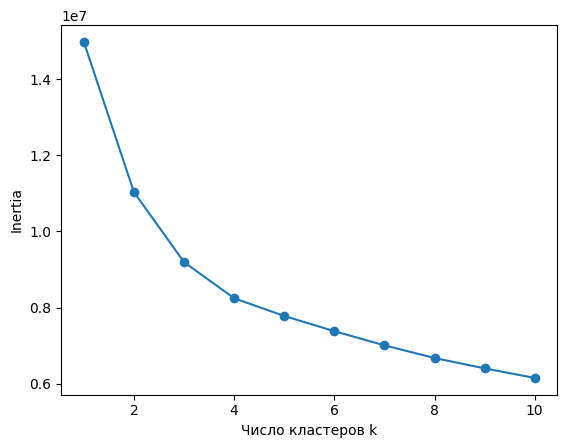

In [79]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
ks = range(1,11)

for k in ks:
    km = KMeans(n_clusters=k, random_state=12, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
plt.plot(ks, inertias, marker='o')
plt.xlabel('Число кластеров k')
plt.ylabel('Inertia')
plt.show()

Для выбранного количества кластеров обучи итоговую модель (используй K-Means из модуля sklearn.cluster с параметром init='k-means++'), поставь в соответствие каждому клиенту его прогнозный кластер.

In [80]:
km = KMeans(n_clusters=4, init='k-means++', random_state=42, n_init=10)
labels = km.fit_predict(X_scaled)

Проанализируй получившиеся результаты:
построй histplot и kdeplot для каждого признака в разрезах прогнозных кластеров.

In [91]:
features_pd.columns = [
    'avg_tran', 'sum_tran', 'count_tran', 'count_val',
    'count_oper', 'count_card', 'count_group_card',
    'proc_eco_flag', 'count_payment', 'procent_income_flag',
    'count_mcc', 'count_country', 'count_city', 'mean_hour_diff',
    'week_mean', 'procent_weekend'
]

plot_df = features_pd.copy()
plot_df['cluster'] = labels  
plot_df

,avg_tran,sum_tran,count_tran,count_val,count_oper,count_card,count_group_card,proc_eco_flag,count_payment,procent_income_flag,count_mcc,count_country,count_city,mean_hour_diff,week_mean,procent_weekend,cluster
client_id,,,,,,,,,,,,,,,,,
000000,0.410982,571.265619,1390,5,5,5,2,0.155396,5,0.125180,75,12,22,6.158273,26.730769,0.280576,1
000006,0.420287,230.317477,548,4,3,2,2,0.069343,4,0.034672,49,7,5,15.341241,10.960000,0.251825,1
000014,0.345275,188.865638,547,3,6,5,2,0.351005,4,0.098720,43,6,17,15.665448,12.155556,0.254113,1
00001d,0.309726,23.539147,76,1,3,2,2,0.000000,5,0.157895,7,1,1,85.328947,3.166667,0.250000,0
000026,0.357270,49.303200,138,1,3,2,2,0.021739,3,0.014493,21,1,5,59.710145,3.631579,0.239130,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ffffc9,0.363387,45.786749,126,1,5,1,2,0.000000,4,0.119048,27,1,3,54.103175,4.666667,0.341270,0
ffffdf,0.278071,43.935236,158,1,3,2,2,0.094937,2,0.031646,11,1,4,28.164557,5.642857,0.170886,0
fffff3,0.414153,89.042967,215,1,5,3,3,0.023256,4,0.051163,34,2,7,38.530233,7.678571,0.320930,3


In [92]:
sample = plot_df.sample(100_000, random_state=42)

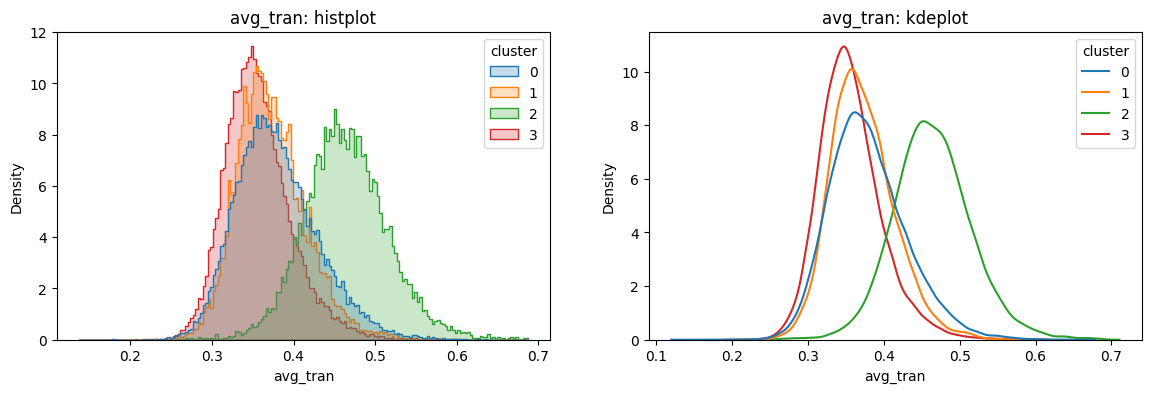

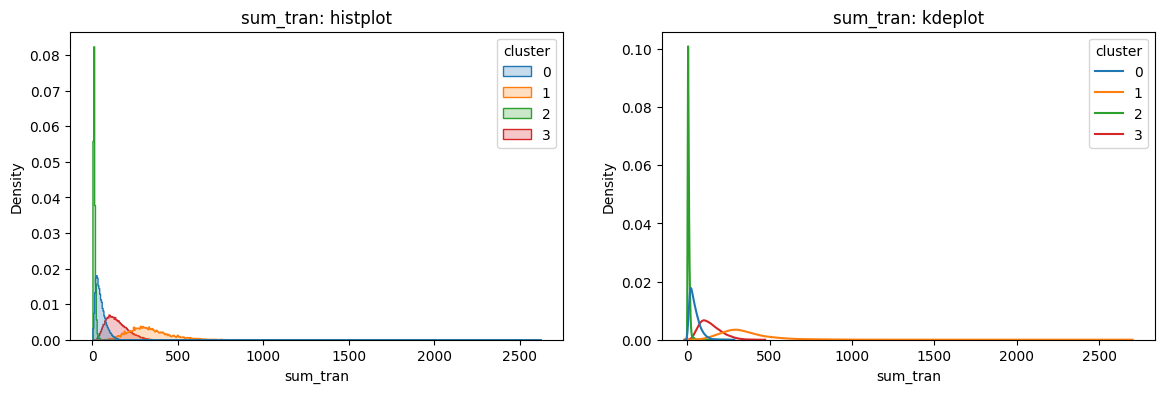

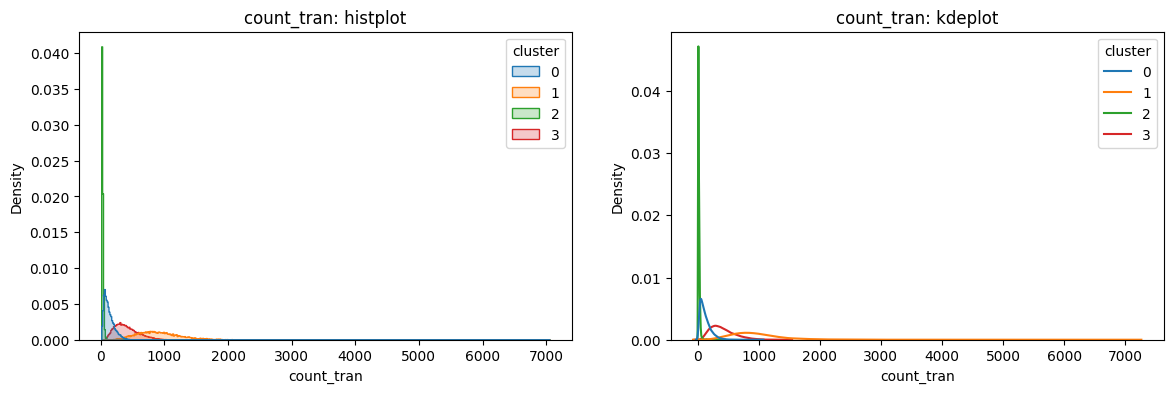

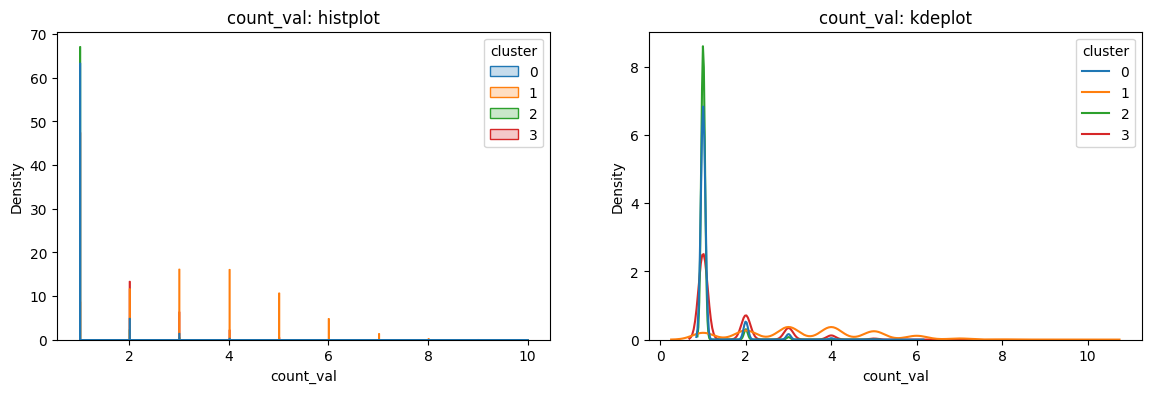

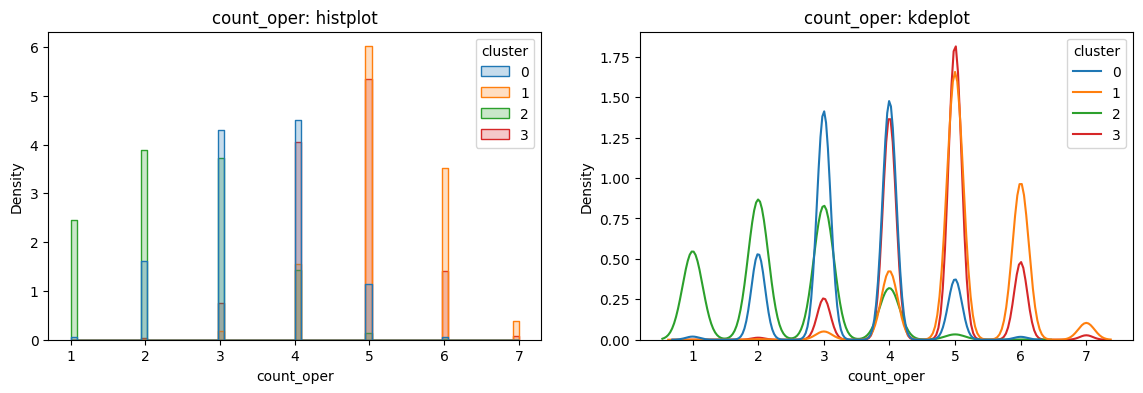

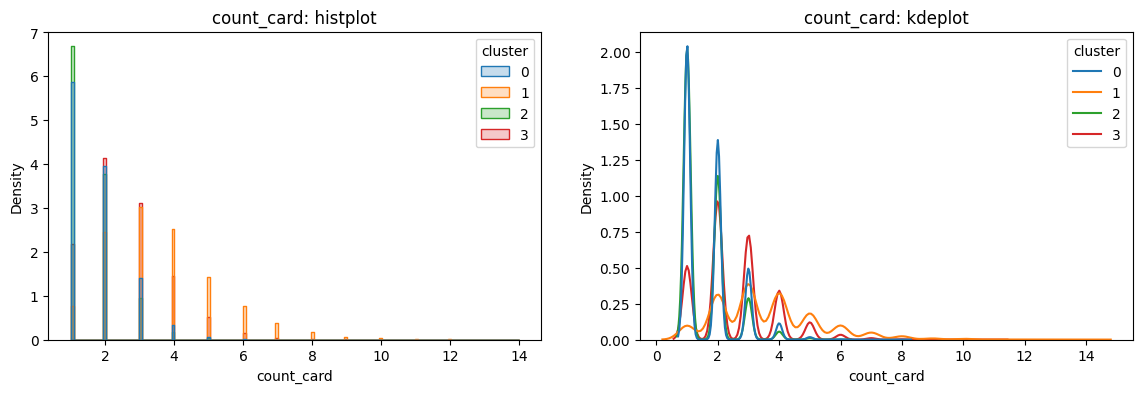

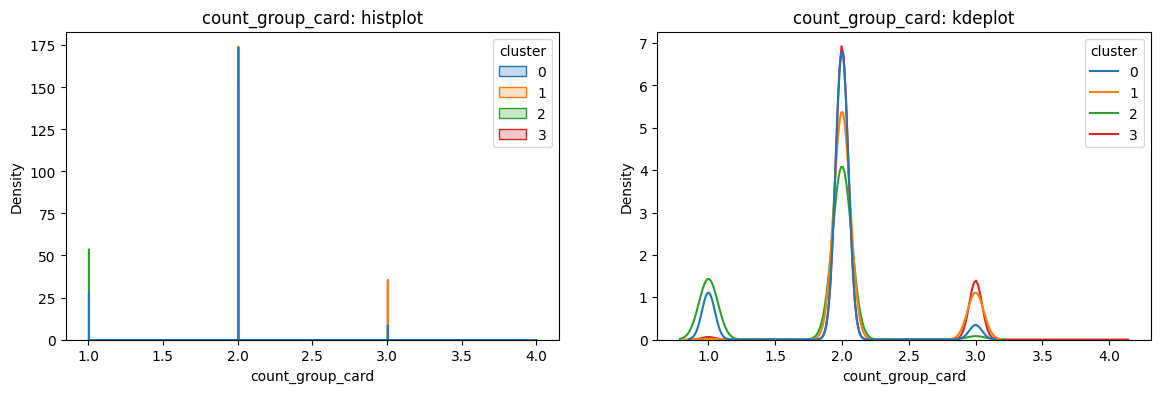

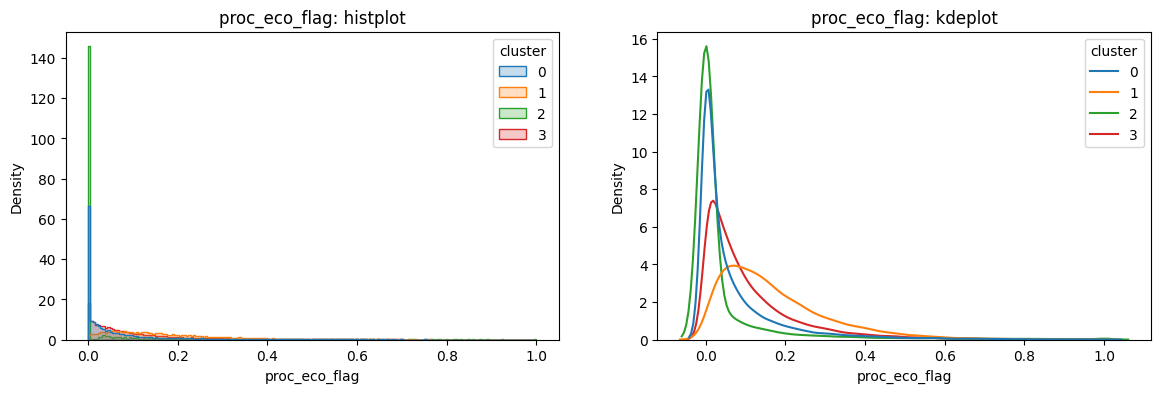

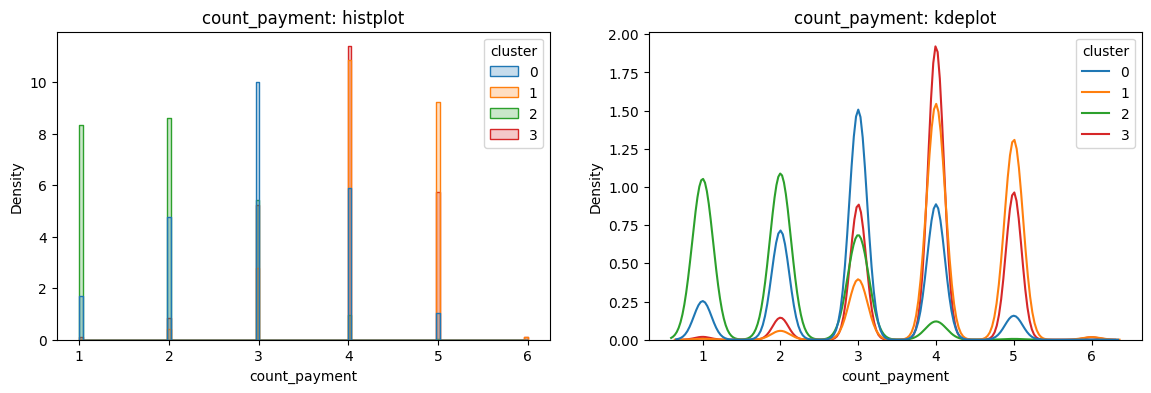

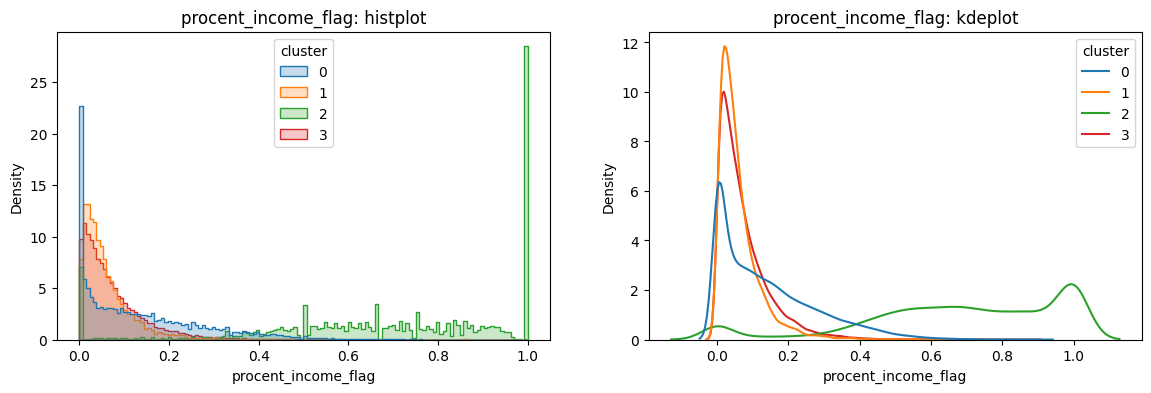

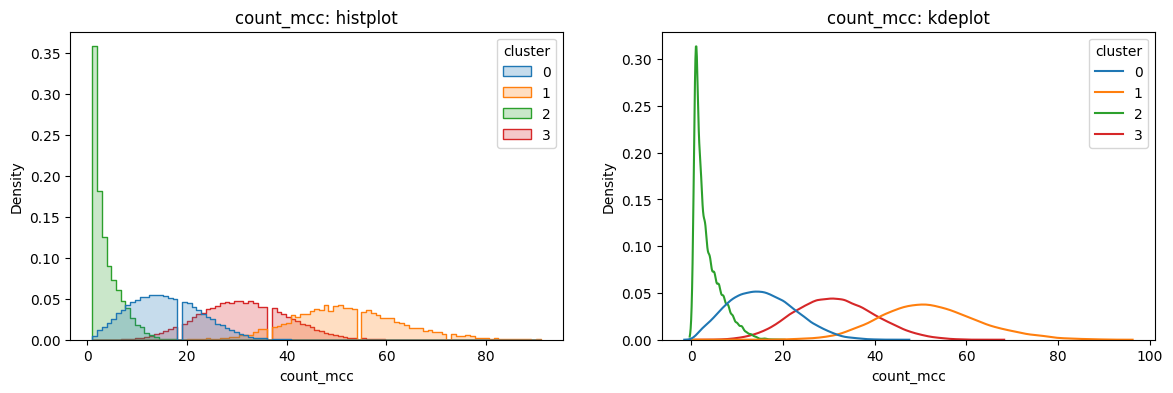

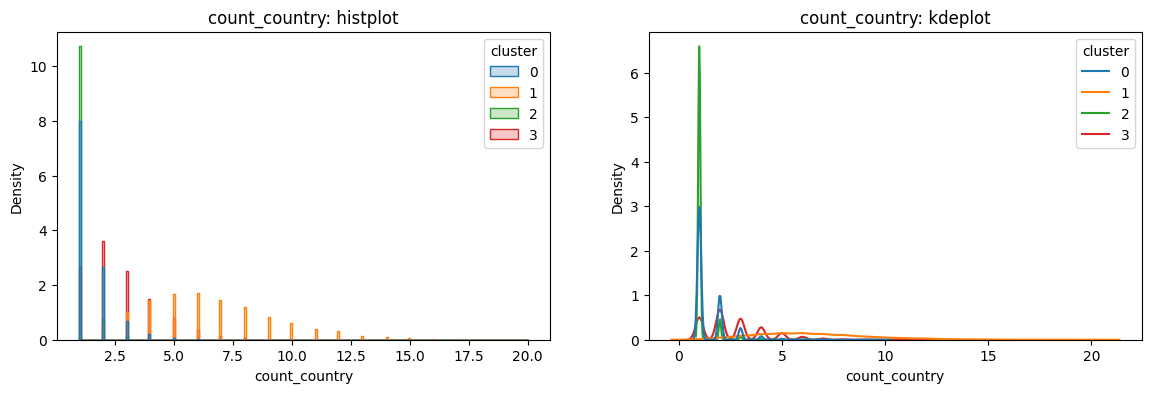

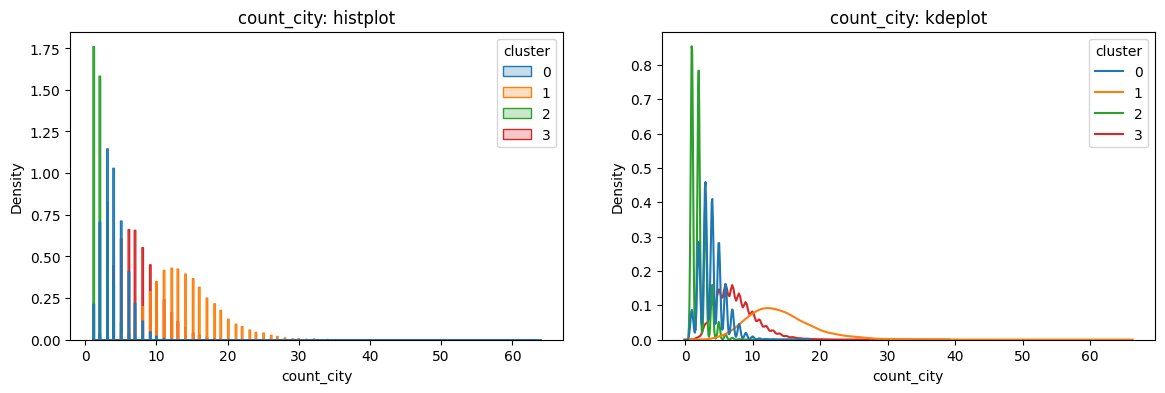

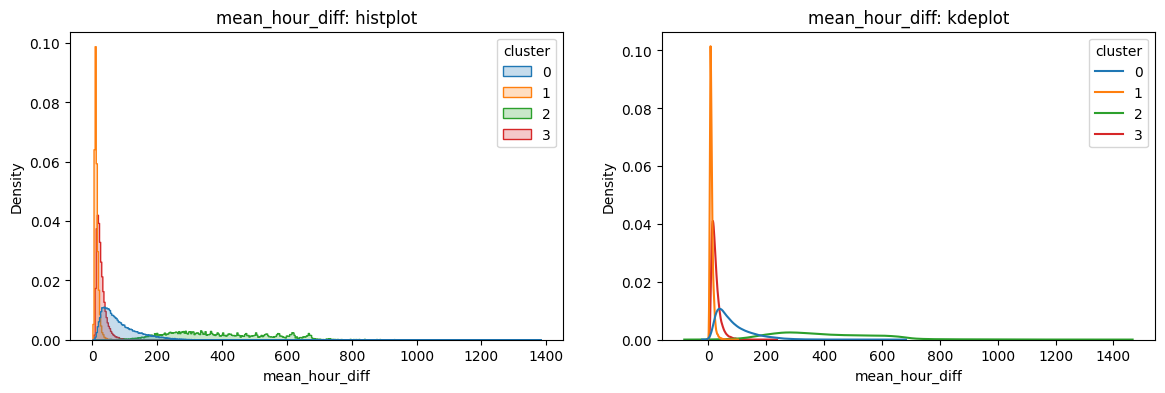

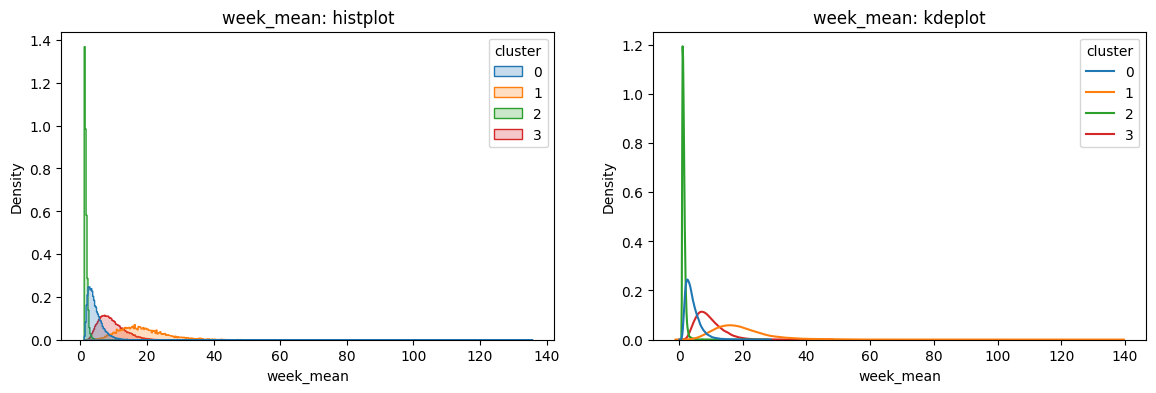

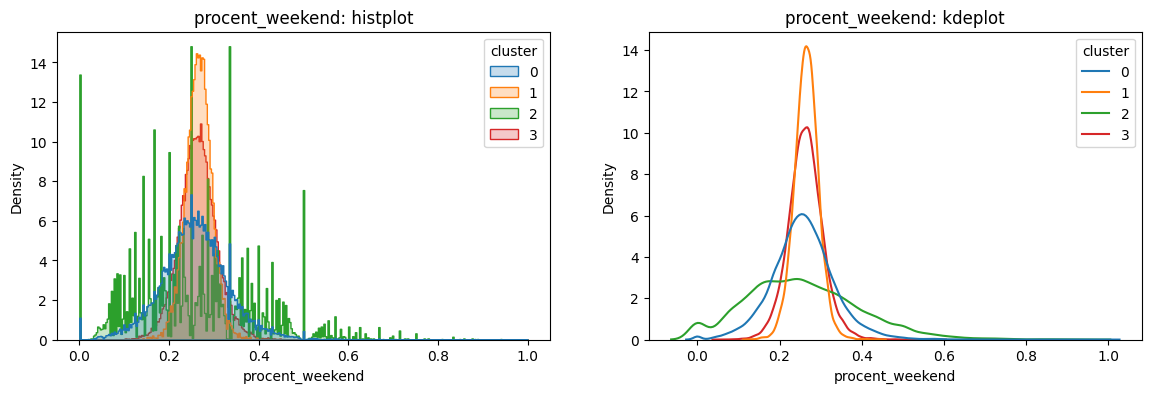

In [94]:
import seaborn as sns
import matplotlib.pyplot as plt

sample = plot_df.sample(100_000, random_state=42)
sample['cluster'] = sample['cluster'].astype('category')

for col in plot_df.columns.drop('cluster'):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    sns.histplot(data=sample, x=col, hue='cluster', element='step',
                 stat='density', common_norm=False, ax=axes[0])
    sns.kdeplot(data=sample, x=col, hue='cluster',
                common_norm=False, ax=axes[1])

    axes[0].set_title(f'{col}: histplot')
    axes[1].set_title(f'{col}: kdeplot')
    plt.show()

In [87]:
print(list(plot_df.columns))
print(plot_df.columns[plot_df.columns.duplicated()])

['amnt', 'amnt', 'amnt', 'currency', 'operation_kind', 'card_type', 'operation_type_group', 'ecommerce_flag', 'payment_system', 'income_flag', 'mcc', 'country', 'city', 'hour_diff', 0, 'day_of_week', 'cluster']
Index(['amnt', 'amnt'], dtype='object')
